## THỰC NGHIỆM B - ẢNH HƯỞNG CỦA SỐ NƠ-RON TẦNG ẨN

### 1. Mục tiêu
Khảo sát ảnh hưởng của độ rộng mạng MLP đến khả năng xấp xỉ hàm Gaussian hai chiều. Mạng có đúng một tầng ẩn, số nơ-ron khảo sát từ 1 đến 10.

### 2. Chỉ số và đầu ra
Ghi Validation MSE/RMSE/MAE, Test MSE/RMSE/MAE, thời gian huấn luyện, epoch có validation loss thấp nhất, train/validation loss theo epoch và checkpoint từng lần chạy.

### 3. Import thư viện, baseline và kiểm tra dữ liệu

In [1]:
from pathlib import Path
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import config as cfg
from dataset import get_all_loaders
from model import MLPRegressor
from train import train_model
from evaluate import evaluate_model

PROJECT_DIR = Path.cwd()
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints"
for folder in (RESULTS_DIR, FIGURES_DIR, CHECKPOINT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

BATCH_SIZE = 64
EPOCHS = 200
LEARNING_RATE = 0.01
SEEDS = list(getattr(cfg, "TRAIN_SEEDS", [0, 1, 2]))
DEVICE = cfg.get_device()

if not (PROJECT_DIR / "data.py").exists():
    raise FileNotFoundError("Không tìm thấy data.py.")

import shutil
cfg.DATA_DIR.mkdir(parents=True, exist_ok=True)
for split in ("train", "val", "test"):
    target = cfg.DATA_DIR / f"{split}.csv"
    source = PROJECT_DIR / f"{split}.csv"
    if not target.exists() and source.exists():
        shutil.copy2(source, target)
    if not target.exists():
        raise FileNotFoundError(
            f"Thiếu {target}. Hãy đặt {split}.csv vào thư mục data/ "
        )

print(f"Device: {DEVICE} | Seeds: {SEEDS}")
print(f"Train/Validation/Test: {cfg.DATA_DIR}")

Đã tạo thành công file model.py!
Đã tạo thành công file train.py!
Đã tạo thành công file evaluate.py!
Device: cpu | Seeds: [0, 1, 2]
Train/Validation/Test: D:\Hocsau_thuchanh\BTL01\CODETV4\data


### 4. Hàm hỗ trợ đánh giá validation và tổng hợp kết quả

In [2]:
def evaluate_loader_mse_mae(model, loader, device):
    """Đánh giá trên loader được chỉ định; không cập nhật trọng số."""
    model.eval()
    predictions, targets = [], []
    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            pred = model(x_batch).detach().cpu().numpy().reshape(-1)
            predictions.append(pred)
            targets.append(y_batch.detach().cpu().numpy().reshape(-1))
    y_pred = np.concatenate(predictions)
    y_true = np.concatenate(targets)
    mse = float(np.mean((y_true - y_pred) ** 2))
    mae = float(np.mean(np.abs(y_true - y_pred)))
    return mse, float(np.sqrt(mse)), mae


def summarize_runs(df_runs, group_col):
    """Tổng hợp mean/std cho các metric; không lấy trung bình cột Seed."""
    metric_cols = [
        "Val_MSE", "Val_RMSE", "Val_MAE",
        "Test_MSE", "Test_RMSE", "Test_MAE",
        "Train_Time_Sec", "Best_Epoch"
    ]
    grouped = df_runs.groupby(group_col)[metric_cols].agg(["mean", "std"])
    grouped.columns = [f"{metric}_{stat.upper()}" for metric, stat in grouped.columns]
    return grouped.reset_index()


def save_loss_history(records, filename):
    df = pd.DataFrame(records)
    df.to_csv(RESULTS_DIR / filename, index=False)
    return df


def plot_mean_loss(df_loss, group_col, group_values, title, output_path, ncols=2):
    """Vẽ mean train/validation loss theo epoch, trung bình trên các seed."""
    mean_loss = (
        df_loss.groupby([group_col, "Epoch"], as_index=False)[["Train_Loss", "Val_Loss"]]
        .mean()
    )
    nrows = int(np.ceil(len(group_values) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7*ncols, 4*nrows), squeeze=False)
    for value, ax in zip(group_values, axes.ravel()):
        part = mean_loss[mean_loss[group_col] == value]
        ax.plot(part["Epoch"], part["Train_Loss"], label="Train loss")
        ax.plot(part["Epoch"], part["Val_Loss"], label="Validation loss")
        ax.set_title(f"{group_col} = {value}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MSE loss")
        ax.grid(True, alpha=0.3)
        ax.legend()
    for ax in axes.ravel()[len(group_values):]:
        ax.set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(output_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### 5. Chạy thực nghiệm B
Mỗi cặp (số nơ-ron, seed) được khởi tạo và huấn luyện độc lập. Best epoch được xác định bằng validation loss; sau đó mới đánh giá tập test.

In [3]:
def run_experiment_B():
    run_records, loss_records = [], []
    neuron_values = list(range(1, 11))

    for n_neurons in neuron_values:
        for seed in SEEDS:
            cfg.set_seed(seed)
            train_loader, val_loader, test_loader = get_all_loaders(
                batch_size=BATCH_SIZE, seed=seed
            )
            model = MLPRegressor(
                input_dim=2, hidden_dim=n_neurons, num_layers=1, output_dim=1
            )

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            start = time.perf_counter()
            model, train_losses, val_losses = train_model(
                train_loader, val_loader, model,
                epochs=EPOCHS, lr=LEARNING_RATE, device=DEVICE
            )
            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
            elapsed = time.perf_counter() - start

            # Epoch tốt nhất được xác định chỉ từ validation loss.
            best_epoch_idx = int(np.argmin(val_losses))
            best_epoch = best_epoch_idx + 1
            val_mse, val_rmse, val_mae = evaluate_loader_mse_mae(
                model, val_loader, DEVICE
            )

            # Test chỉ được gọi sau khi hoàn tất huấn luyện; không dùng để chọn cấu hình.
            test_metrics, _ = evaluate_model(model, test_loader, device=DEVICE)

            checkpoint_path = CHECKPOINT_DIR / f"model_B_neurons{n_neurons}_seed{seed}.pt"
            torch.save({
                "model_state_dict": model.state_dict(),
                "experiment": "B",
                "num_layers": 1,
                "hidden_dim": n_neurons,
                "seed": seed,
                "best_epoch": best_epoch,
                "best_val_loss": float(val_losses[best_epoch_idx]),
                "batch_size": BATCH_SIZE,
                "epochs": EPOCHS,
                "learning_rate": LEARNING_RATE,
            }, checkpoint_path)

            run_records.append({
                "Num_Neurons": n_neurons, "Num_Layers": 1, "Seed": seed,
                "Best_Epoch": best_epoch,
                "Train_Loss_At_Best_Epoch": float(train_losses[best_epoch_idx]),
                "Val_Loss_At_Best_Epoch": float(val_losses[best_epoch_idx]),
                "Val_MSE": val_mse, "Val_RMSE": val_rmse, "Val_MAE": val_mae,
                "Test_MSE": float(test_metrics["MSE"]),
                "Test_RMSE": float(test_metrics["RMSE"]),
                "Test_MAE": float(test_metrics["MAE"]),
                "Train_Time_Sec": elapsed,
                "Checkpoint": str(checkpoint_path.relative_to(PROJECT_DIR)),
            })
            for epoch, (tr_loss, va_loss) in enumerate(zip(train_losses, val_losses), start=1):
                loss_records.append({
                    "Num_Neurons": n_neurons, "Seed": seed, "Epoch": epoch,
                    "Train_Loss": float(tr_loss), "Val_Loss": float(va_loss)
                })
            print(f"B | neurons={n_neurons:2d} | seed={seed} | "
                  f"val_mse={val_mse:.8g} | test_mse={test_metrics['MSE']:.8g} | "
                  f"time={elapsed:.2f}s")

    df_runs = pd.DataFrame(run_records)
    df_summary = summarize_runs(df_runs, "Num_Neurons")
    df_loss = pd.DataFrame(loss_records)
    df_runs.to_csv(RESULTS_DIR / "results_B_raw.csv", index=False)
    df_summary.to_csv(RESULTS_DIR / "results_B.csv", index=False)
    df_loss.to_csv(RESULTS_DIR / "loss_history_B.csv", index=False)
    return df_runs, df_summary, df_loss


df_runs_B, df_summary_B, df_losses_B = run_experiment_B()
display(df_summary_B.round(8))

B | neurons= 1 | seed=0 | val_mse=0.0032425036 | test_mse=0.0016942739 | time=29.52s
B | neurons= 1 | seed=1 | val_mse=0.003271898 | test_mse=0.0018843221 | time=22.98s
B | neurons= 1 | seed=2 | val_mse=0.0029893816 | test_mse=0.0018335806 | time=24.55s
B | neurons= 2 | seed=0 | val_mse=0.0028979247 | test_mse=0.0016998723 | time=23.02s
B | neurons= 2 | seed=1 | val_mse=0.0016409504 | test_mse=0.0014007549 | time=23.53s
B | neurons= 2 | seed=2 | val_mse=0.0019736718 | test_mse=0.0012650505 | time=22.44s
B | neurons= 3 | seed=0 | val_mse=0.00195043 | test_mse=0.0011708101 | time=24.86s
B | neurons= 3 | seed=1 | val_mse=0.0010296908 | test_mse=0.00072794623 | time=22.59s
B | neurons= 3 | seed=2 | val_mse=0.0029151766 | test_mse=0.0017214173 | time=24.79s
B | neurons= 4 | seed=0 | val_mse=0.00094727642 | test_mse=0.00050201302 | time=23.46s
B | neurons= 4 | seed=1 | val_mse=0.00035705874 | test_mse=0.00029088787 | time=23.27s
B | neurons= 4 | seed=2 | val_mse=0.0012169057 | test_mse=0.000

,Num_Neurons,Val_MSE_MEAN,Val_MSE_STD,Val_RMSE_MEAN,Val_RMSE_STD,Val_MAE_MEAN,Val_MAE_STD,Test_MSE_MEAN,Test_MSE_STD,Test_RMSE_MEAN,Test_RMSE_STD,Test_MAE_MEAN,Test_MAE_STD,Train_Time_Sec_MEAN,Train_Time_Sec_STD,Best_Epoch_MEAN,Best_Epoch_STD
0,1,0.003168,0.000155,0.056273,0.001390,0.042933,0.001583,0.001804,0.000098,0.042464,0.001165,0.035720,0.002135,25.682348,3.414141,98.333333,35.218366
1,2,0.002171,0.000651,0.046256,0.006848,0.032369,0.005596,0.001455,0.000222,0.038075,0.002886,0.029046,0.003875,22.993732,0.543401,164.000000,48.383882
2,3,0.001965,0.000943,0.043415,0.010971,0.031574,0.008613,0.001207,0.000498,0.034229,0.007255,0.026738,0.006872,24.083050,1.293077,138.666667,67.715089
3,4,0.000840,0.000440,0.028186,0.008303,0.020468,0.006499,0.000482,0.000181,0.021664,0.004287,0.016444,0.004059,23.368728,0.096958,97.666667,64.033845
4,5,0.000337,0.000006,0.018348,0.000173,0.012629,0.000675,0.000256,0.000046,0.015939,0.001482,0.011043,0.001755,24.437558,0.653895,139.333333,29.905406
5,6,0.000463,0.000213,0.021175,0.004729,0.015336,0.003811,0.000400,0.000254,0.019395,0.006026,0.014225,0.005166,25.497278,3.914720,146.333333,23.459184
6,7,0.000340,0.000026,0.018436,0.000721,0.013461,0.000968,0.000276,0.000052,0.016553,0.001590,0.012189,0.001084,27.716328,0.544443,128.666667,53.678053
7,8,0.000247,0.000114,0.015446,0.003563,0.011241,0.002427,0.000180,0.000144,0.012777,0.005069,0.009385,0.004076,29.874227,1.382462,141.333333,72.610835
8,9,0.000272,0.000163,0.015974,0.005040,0.012118,0.004343,0.000201,0.000167,0.013358,0.005827,0.010202,0.004904,28.773481,0.885314,135.333333,57.882064
9,10,0.000224,0.000120,0.014616,0.003955,0.011477,0.003646,0.000170,0.000134,0.012403,0.004865,0.009559,0.004369,27.214315,0.448327,144.000000,32.908965


### 6. Trực quan hóa sai số
Các thanh sai số biểu diễn mean ± standard deviation trên ba seed. Chọn cấu hình dựa trên Validation MSE, không dựa trên Test MSE.

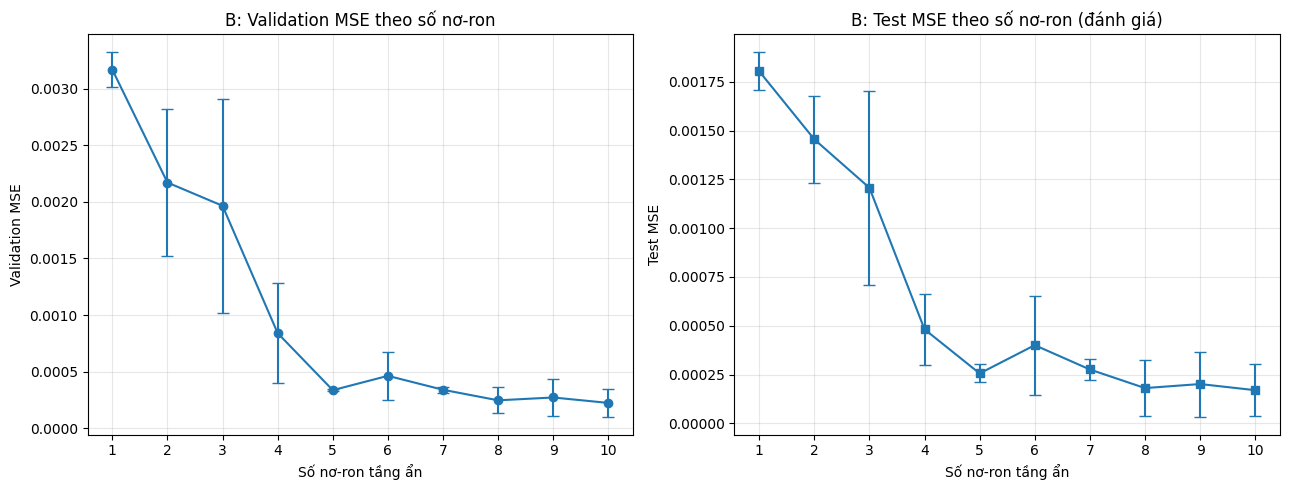

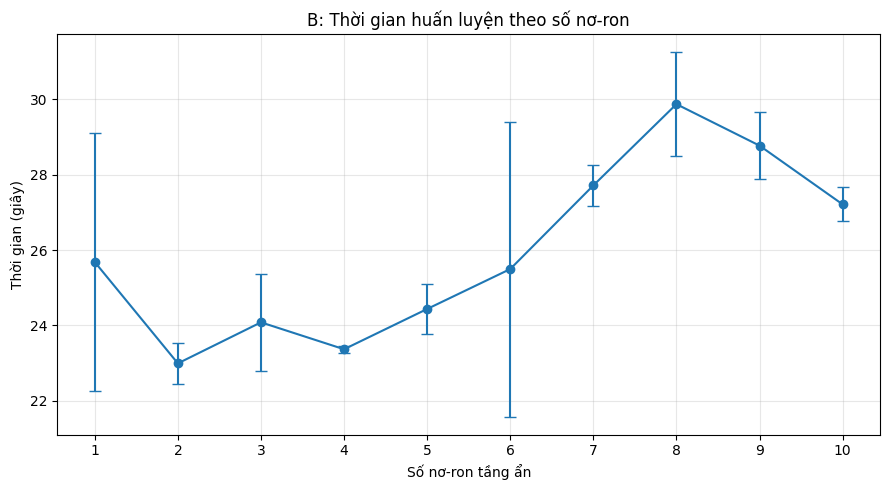

In [4]:
x = df_summary_B["Num_Neurons"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].errorbar(x, df_summary_B["Val_MSE_MEAN"], yerr=df_summary_B["Val_MSE_STD"], marker="o", capsize=4)
axes[0].set(title="B: Validation MSE theo số nơ-ron", xlabel="Số nơ-ron tầng ẩn", ylabel="Validation MSE")
axes[0].set_xticks(range(1, 11)); axes[0].grid(True, alpha=0.3)
axes[1].errorbar(x, df_summary_B["Test_MSE_MEAN"], yerr=df_summary_B["Test_MSE_STD"], marker="s", capsize=4)
axes[1].set(title="B: Test MSE theo số nơ-ron (đánh giá)", xlabel="Số nơ-ron tầng ẩn", ylabel="Test MSE")
axes[1].set_xticks(range(1, 11)); axes[1].grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "plot_B_errors.png", dpi=180, bbox_inches="tight")
plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(x, df_summary_B["Train_Time_Sec_MEAN"], yerr=df_summary_B["Train_Time_Sec_STD"], marker="o", capsize=4)
ax.set(title="B: Thời gian huấn luyện theo số nơ-ron", xlabel="Số nơ-ron tầng ẩn", ylabel="Thời gian (giây)")
ax.set_xticks(range(1, 11)); ax.grid(True, alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES_DIR / "plot_B_training_time.png", dpi=180, bbox_inches="tight")
plt.show(); plt.close(fig)

### 7. Đường cong hội tụ và nhận xét underfitting/overfitting
Đường cong dưới đây là trung bình theo seed. Train loss và validation loss đều cao có thể gợi ý underfitting; train loss giảm nhưng validation loss tăng/khoảng cách mở rộng có thể gợi ý overfitting. Chỉ kết luận khi biểu đồ thực tế có dấu hiệu tương ứng.

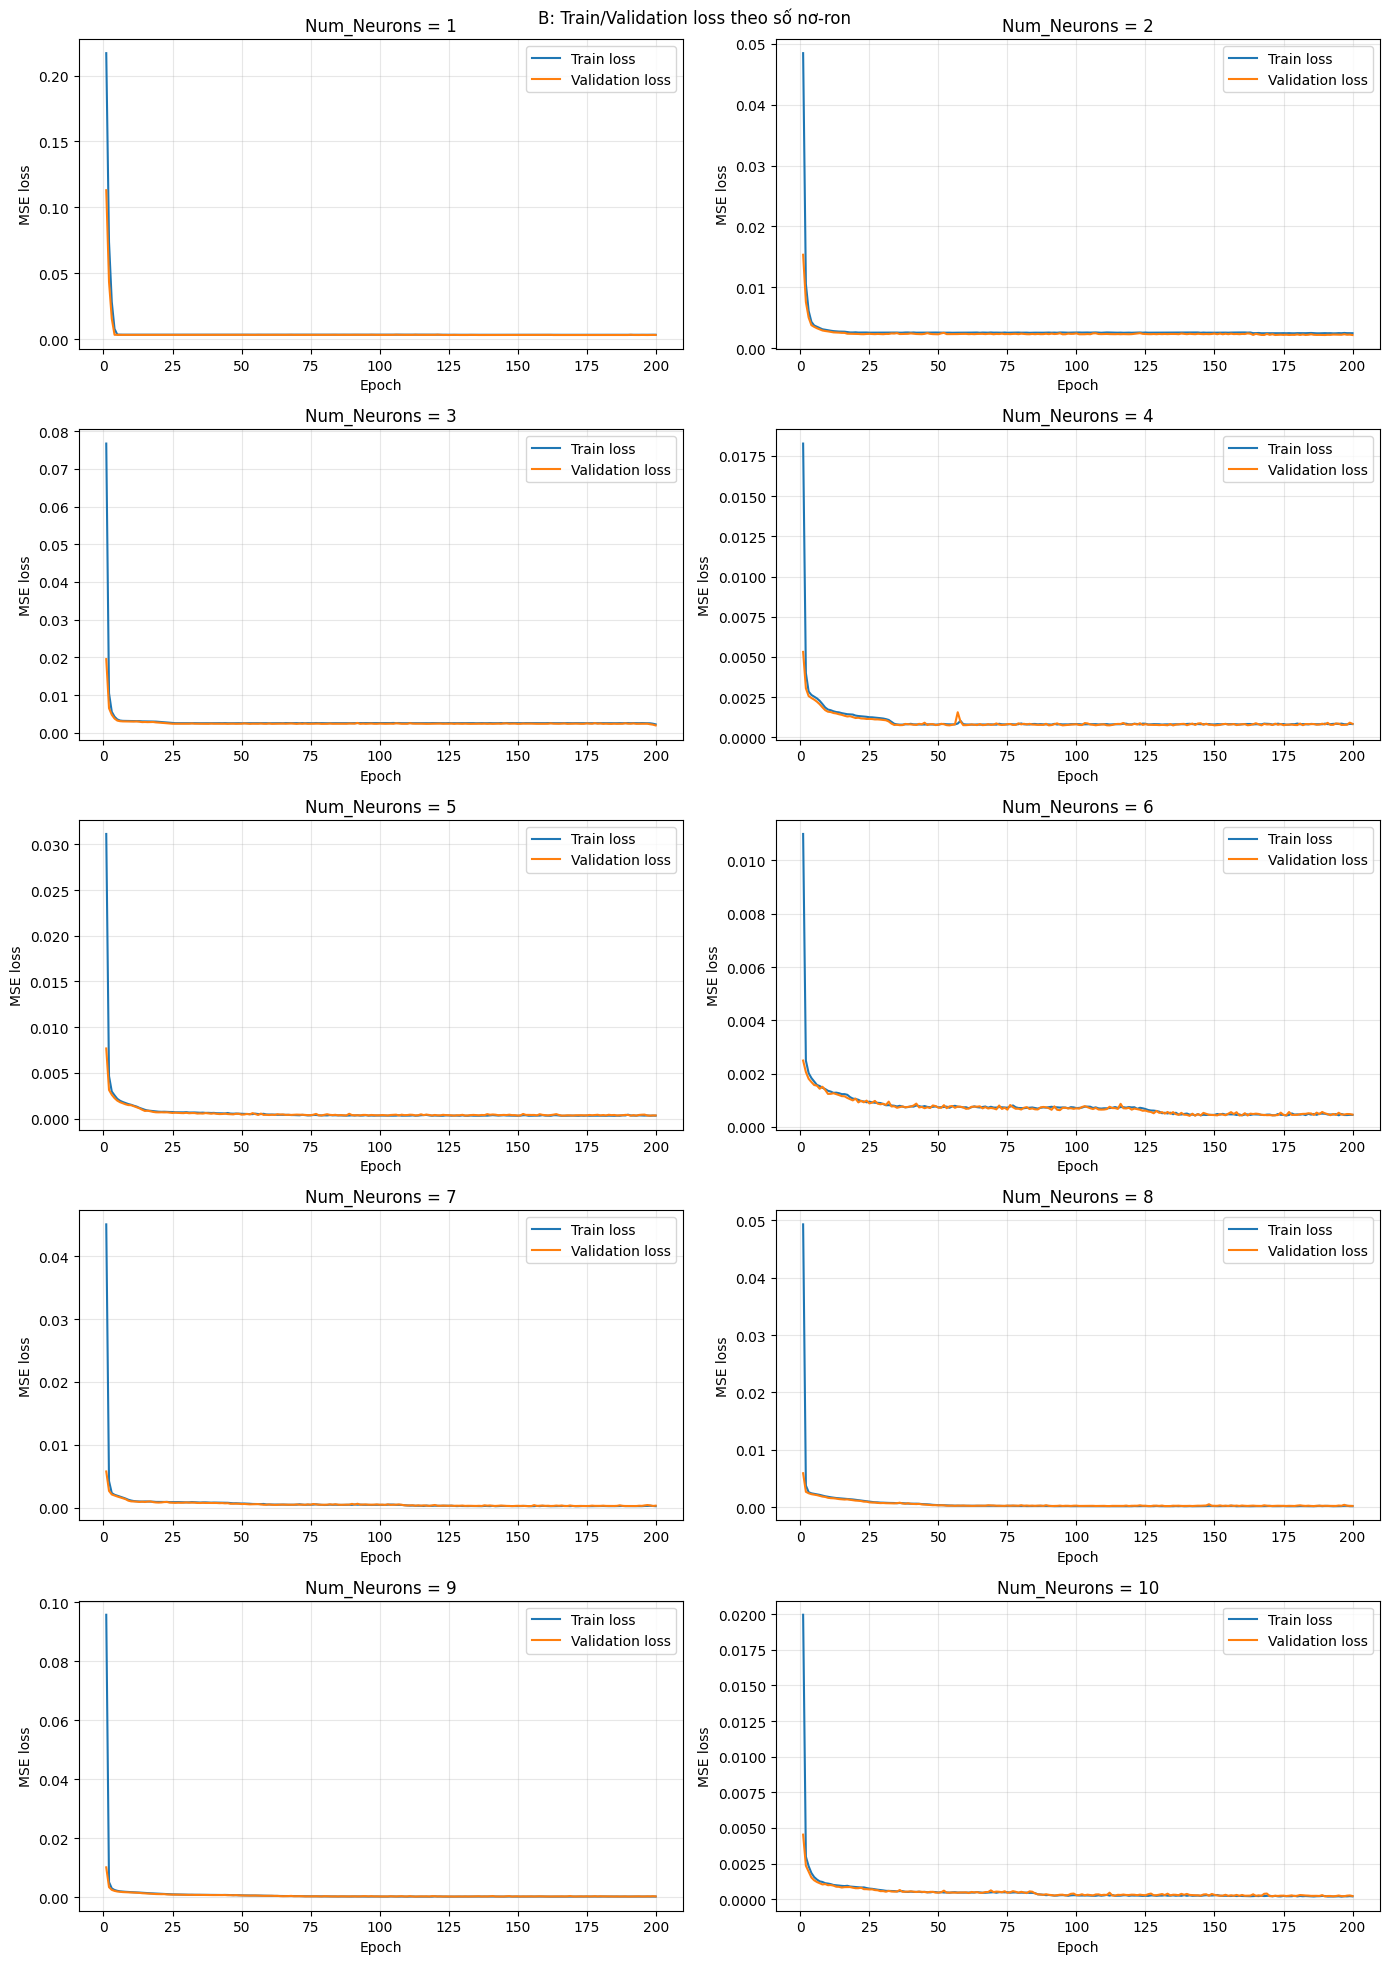

In [5]:
plot_mean_loss(df_losses_B, "Num_Neurons", list(range(1, 11)),
               "B: Train/Validation loss theo số nơ-ron",
               FIGURES_DIR / "plot_B_loss_curves.png", ncols=2)